# كشف صور الوجوه المولَّدة بالذكاء الاصطناعي ودراسة أثر ضغط JPEG على دقة الكشف
مشروع PyTorch وMobileNetV3-Small وواجهة Gradio عربية.

**ابدأ بالتجربة السريعة الافتراضية**: تختبر البرمجيات على أشكال اصطناعية في CPU ولا تُثبت دقة كشف الوجوه. للتجربة العلمية اختر بيانات الوجوه ووضع التدريب الكامل في الخلية 2. لا توجد نتائج تدريب كامل مُختلقة. راجع `README_AR.md` و`docs/DATASET_CARD_AR.md` داخل ZIP.

ارفع هذا الدفتر إلى Colab، وجهّز ملف `facejpeg_project.zip` بجواره على جهازك. تتضمن الحزمة الكود وأوزان تجربة سلامة التشغيل، ولا تتضمن بيانات وجوه من Kaggle. لكل مرحلة شرح ونتيجة متوقعة. لا ترفع مفاتيح وصول في المحادثة أو في خلايا الدفتر.

## 1 — فتح الحزمة وتثبيت المتطلبات
في Colab ستختار ZIP المشروع **مرة واحدة**. تتحقق الخلية من مسارات الأرشيف وتنتقل إلى مجلد المشروع. عند التشغيل المحلي افتح الدفتر من المجلد المستخرج. الناتج المتوقع: ظهور مجلد المشروع وإصدارات PyTorch وTorchvision ووجود GPU أو عدمه. لا تُعطّل التحقق من TLS إذا فشل التنزيل.

In [1]:
import os, sys, subprocess, zipfile
from pathlib import Path
try:
    import google.colab
    IN_COLAB = True
except ImportError:
    IN_COLAB = False
if not (Path.cwd() / "requirements.txt").exists():
    candidates = list(Path("/content").glob("**/facejpeg_project/requirements.txt")) if Path("/content").exists() else []
    if candidates:
        os.chdir(candidates[0].parent)
    elif IN_COLAB:
        from google.colab import files
        print("اختر ZIP المشروع، لا ZIP البيانات، في هذه المرحلة")
        uploaded = files.upload()
        project_zip = next((n for n in uploaded if n.lower().endswith(".zip")), None)
        if project_zip is None:
            raise ValueError("يجب اختيار ZIP المشروع")
        dest = Path("/content/facejpeg_delivery").resolve()
        dest.mkdir(exist_ok=True)
        with zipfile.ZipFile(project_zip) as z:
            for i in z.infolist():
                target = (dest / i.filename).resolve()
                if not target.is_relative_to(dest) or (i.external_attr >> 16) & 0o170000 == 0o120000:
                    raise ValueError("Unsafe ZIP")
                if target.exists() and not i.is_dir():
                    raise FileExistsError("استُخرج المشروع سابقًا؛ انتقل إلى مجلده بدل استبدال الملفات")
            z.extractall(dest)
        os.chdir(next(dest.glob("**/requirements.txt")).parent)
    else:
        raise FileNotFoundError("شغّل الدفتر من مجلد المشروع المستخرج")
PROJECT = Path.cwd()
subprocess.run([sys.executable, "-m", "pip", "install", "-r", "requirements.txt", "--quiet"], check=True)
if str(PROJECT) not in sys.path:
    sys.path.insert(0, str(PROJECT))
import torch, torchvision
print("Project:", PROJECT)
print("PyTorch:", torch.__version__, "Torchvision:", torchvision.__version__, "GPU:", torch.cuda.is_available())

Project: /workspace/Final-Projects
PyTorch: 2.5.1+cpu Torchvision: 0.20.1+cpu GPU: False


## 2 — اختيار نمط التشغيل
`QUICK=True` يستخدم CPU وعينة صغيرة وتدريب رأس التصنيف فقط. `SOURCE='fixture'` هو اختبار برمجي بلا بيانات وجوه. للتدريب العلمي اختر `SOURCE='kaggle'` أو `zip` أو `drive`، ثم `QUICK=False` واختر GPU من إعدادات Colab. سيكتشفه الكود تلقائيًا.

غيّر `EXPERIMENT` عند تغيير البيانات أو النمط؛ لا تخلط تجربة سريعة بتدريب كامل. `EPOCHS` هو إجمالي عدد الحقبات المطلوب، بما فيها المحفوظة سابقًا. لا يُجرى ضغط JPEG في التدريب في هذا البروتوكول.

In [2]:
QUICK = True
SOURCE = "fixture"  # fixture | kaggle | zip | drive
USE_DRIVE = False  # اجعله True لحفظ التقدم بعد انقطاع الجلسة
EXPERIMENT = "smoke_demo"  # اسم جديد لكل تجربة مستقلة
EPOCHS = 2 if QUICK else 10
BATCH_SIZE = 8 if QUICK else 32
MAX_PER_CLASS = 40 if QUICK else None
METADATA_CSV = None  # ملف اختياري path,identity,source_id؛ راجع الدليل
RAW_DRIVE_PATH = "/content/drive/MyDrive/facejpeg/raw"
SHARE_GRADIO = True  # في Colab فقط: رابط عام مؤقت عند تشغيل خلية الواجهة
assert SOURCE in {"fixture", "kaggle", "zip", "drive"}
if SOURCE == "fixture" and not QUICK:
    raise ValueError("البيانات الهندسية للاختبار السريع فقط؛ اختر بيانات وجوه للتدريب الكامل")

## 3 — الحفظ والاستكمال من Google Drive
عند `USE_DRIVE=True` تُحفظ الصور الموحّدة وملفات التقسيم وأفضل نموذج و`last.pt` في Drive. بعد الانقطاع أعد فتح الدفتر والحزمة، وشغّل الخلايا 1–7 بالإعدادات والاسم نفسيهما. لا تحتاج إعادة تنزيل البيانات إذا كان `manifest.csv` والصور المجهزة محفوظين. تُكتب نقطة استكمال بعد كل حقبة؛ أي عمل في حقبة غير مكتملة سيُعاد. الناتج: مسار دائم للتجربة أو مسار محلي مؤقت.

In [3]:
if USE_DRIVE or SOURCE == "drive":
    if not IN_COLAB:
        raise RuntimeError("استخدم مسارًا محليًا أو Google Colab لتركيب Drive")
    from google.colab import drive
    drive.mount("/content/drive")
RUNS_BASE = Path("/content/drive/MyDrive/facejpeg_runs") if USE_DRIVE else PROJECT / "runs"
RUN = RUNS_BASE / EXPERIMENT
PREPARED = RUN / "prepared"
RUN.mkdir(parents=True, exist_ok=True)
print("Experiment:", RUN)

Experiment: /workspace/Final-Projects/runs/smoke_demo


## 4 — البيانات: تنزيل Kaggle أو ZIP أو Drive
المجموعة المقترحة: [140k Real and Fake Faces](https://www.kaggle.com/datasets/xhlulu/140k-real-and-fake-faces)، صور FFHQ فوتوغرافية ووجوه StyleGAN مولّدة بالكامل. ميزانية التنزيل التقريبية **نحو 4 GiB** وليست قياسًا من هذه الجلسة؛ اترك 12–20 GiB للتنزيل والاستخراج والمخرجات. راجع الترخيص الأصلي والاعتمادات في بطاقة البيانات؛ تُستخدم هنا للتعليم غير التجاري. لم يمكن التحقق من صفحة Kaggle الحالية في البيئة السحابية بسبب منع الشبكة.

`kaggle`: تنزيل عام عبر kagglehub؛ قد يطلب حسابًا/قبول شروط على موقع Kaggle. `zip`: اختر ZIP البيانات بعد تنزيله بنفسك. `drive`: ضع البيانات المستخرجة في `RAW_DRIVE_PATH`. المجلدات المطلوبة `raw/real/*.jpg` و`raw/fake/*.jpg`؛ يُقبل أيضًا هيكل Kaggle المتداخل train/real وvalid/fake، ويُعاد تقسيمه بعد فحص التسرب. **عند تعثر Kaggle غيّر SOURCE إلى zip أو drive وأعد الخلية 2 ثم 4**. لا حاجة إلى إرسال مفاتيح. في وضع fixture ينتج الكود 40 شكلًا عشوائيًا لاختبار الحفظ والتنبؤ فقط.

In [4]:
from scripts.make_demo import make_demo
from scripts.download_data import download
from facejpeg.data import safe_extract
RAW_ROOT = None
if (PREPARED / "manifest.csv").exists():
    print("الصور المجهزة موجودة؛ سنستعمل التقسيم المحفوظ ولن نعيد تقسيم البيانات.")
elif SOURCE == "fixture":
    RAW_ROOT = PROJECT / "data" / (EXPERIMENT + "_fixture")
    if not RAW_ROOT.exists():
        make_demo(RAW_ROOT, count=20)
elif SOURCE == "kaggle":
    RAW_ROOT = download(PROJECT / "data/download.json")
elif SOURCE == "zip":
    if not IN_COLAB:
        raise RuntimeError("محليًا: استخرج ZIP وحدد RAW_ROOT مباشرة")
    from google.colab import files
    print("اختر ZIP البيانات")
    uploads = files.upload()
    data_zip = next(n for n in uploads if n.lower().endswith(".zip"))
    RAW_ROOT = safe_extract(data_zip, PROJECT / "data" / (EXPERIMENT + "_raw"))
elif SOURCE == "drive":
    RAW_ROOT = Path(RAW_DRIVE_PATH)
    if not RAW_ROOT.is_dir():
        raise FileNotFoundError(RAW_ROOT)
print("Raw:", RAW_ROOT)

Raw: /workspace/Final-Projects/data/smoke_demo_fixture


## 5 — التدقيق والتقسيم والمعالجة المشتركة
تُقرأ جميع الصور لفحص التلف، والتكرار بالبكسلات، والتشابه بـpHash، وتُجمّع معلومات `identity` و`source_id` إن زوّدتها. تُستبعد التعارضات في التصنيفات، وتُحذف النسخ المتطابقة، وتُبقي النسخ المتقاربة في المجموعة نفسها. ثم تقسيم طبقي تقريبي 70/15/15 **بالمجموعات**؛ قد تختلف نسب الصور حين تختلف أحجام المجموعات. كل فئة تحتاج ثلاث مجموعات مستقلة على الأقل. العينة السريعة تُختار بعد هذا التدقيق.

تُحفظ فروق الصيغ والدقة في CSV، ثم نفس RGB والقص المركزي 224×224 وPNG بلا EXIF لكلا الفئتين بعد التقسيم. لا يضمن pHash اكتشاف كل النسخ ولا يفصل الأشخاص بلا معلومات هوية؛ لا ندّعي استقلال الهوية حين تكون مفقودة. التوحيد يقلل الاختصارات ولا يمحو بصمات الضغط السابقة. الناتج: manifest قابل لإعادة الاستخدام وتقارير تدقيق. فحص 140 ألف صورة قد يستغرق وقتًا؛ لا تُلغِ الفحص في التجربة العلمية.

In [5]:
import json, pandas as pd
from IPython.display import display, Markdown, Image as DisplayImage
from facejpeg.data import prepare
if not (PREPARED / "manifest.csv").exists():
    prepare(RAW_ROOT, PREPARED, metadata=METADATA_CSV, max_per_class=MAX_PER_CLASS,
            data_kind="procedural_fixture" if SOURCE == "fixture" else "research_faces")
audit = json.loads((PREPARED / "audit.json").read_text())
expected_kind = "procedural_fixture" if SOURCE == "fixture" else "research_faces"
assert audit["data_kind"] == expected_kind, "اسم التجربة مستخدم لبيانات مختلفة؛ اختر اسمًا جديدًا"
print(json.dumps(audit, ensure_ascii=False, indent=2))
display(pd.read_csv(PREPARED / "source_format_resolution.csv"))
manifest = pd.read_csv(PREPARED / "manifest.csv")
display(pd.crosstab(manifest.split, manifest.label).rename(columns={0:"فوتوغرافية",1:"مولدة"}))
assert manifest.groupby("group").split.nunique().max() == 1

{
  "raw_root": "/workspace/Final-Projects/data/smoke_demo_fixture",
  "readable": 40,
  "rejected": 0,
  "exact_duplicates_removed": 0,
  "conflict_images_excluded": 0,
  "kept": 40,
  "seed": 42,
  "phash_radius": 4,
  "identity_rows": 0,
  "identity_limitation": "No identity guarantee for rows without identity metadata. pHash is heuristic, not face recognition.",
  "data_kind": "procedural_fixture",
  "counts": {
    "('test', 0)": 3,
    "('test', 1)": 3,
    "('train', 0)": 14,
    "('train', 1)": 14,
    "('val', 0)": 3,
    "('val', 1)": 3
  }
}
{
  "raw_root": "/workspace/Final-Projects/data/smoke_demo_fixture",
  "readable": 40,
  "rejected": 0,
  "exact_duplicates_removed": 0,
  "conflict_images_excluded": 0,
  "kept": 40,
  "seed": 42,
  "phash_radius": 4,
  "identity_rows": 0,
  "identity_limitation": "No identity guarantee for rows without identity metadata. pHash is heuristic, not face recognition.",
  "data_kind": "procedural_fixture",
  "counts": {
    "('test', 0)": 3,

,label,format,count,width_min,width_median,width_max,height_min,height_median,height_max
0,0,PNG,20,224,224.0,224,224,224.0,224
1,1,PNG,20,224,224.0,224,224,224.0,224


label,فوتوغرافية,مولدة
split,,
test,3,3
train,14,14
val,3,3


## 6 — التدريب وحفظ الأفضل والاستكمال
يُحمّل MobileNetV3-Small أوزان ImageNet الرسمية مع تحقق تجزئة التنزيل، ويستبدل الرأس بمخرج ثنائي. الإيقاف المبكر بعد 5 حقبات دون تحسن، واختيار الأفضل بأقل BCE على التحقق. تُختار حدود الحكم الثلاثي من التحقق فقط، بعقوبة أكبر للاتهام الخاطئ. تُحفظ الفئات والمعالجة والحدود مع الأوزان.

الناتج `best.pt` للتنبؤ و`last.pt` مع حالة المحسن للاستكمال وملفات CSV. لا تستخدم مجموعة الاختبار لتعديل هذه الخيارات. الأوزان السريعة على الأشكال الهندسية ليست كاشف وجوه. إذا تعذّر تنزيل الأوزان فلا تتحول سرًا إلى أوزان عشوائية: أصلح الاتصال ثم أعد هذه الخلية.

In [6]:
from facejpeg.train import train
BEST = train(PREPARED, RUN, epochs=EPOCHS, batch_size=BATCH_SIZE,
             quick=QUICK, resume=True, pretrained=True)
display(pd.read_csv(RUN / "history.csv"))
print("Saved:", BEST)
print((RUN / "run_info.json").read_text())

device=cpu; mode=SMOKE_ONLY_NOT_A_FACE_DETECTOR; train=28 val=6
{'epoch': 1, 'train_loss': 0.6590779679162162, 'val_loss': 0.5708073377609253}
{'epoch': 2, 'train_loss': 0.5675910030092511, 'val_loss': 0.5138264199097952}
Saved: /workspace/Final-Projects/runs/smoke_demo/best.pt
{
  "schema_version": 1,
  "architecture": "mobilenet_v3_small",
  "classes": [
    "real",
    "fake"
  ],
  "preprocess": {
    "size": 224,
    "resize": "center_square_bicubic",
    "color": "RGB",
    "mean": [
      0.485,
      0.456,
      0.406
    ],
    "std": [
      0.229,
      0.224,
      0.225
    ],
    "exif_transpose": true,
    "jpeg_subsampling": 2
  },
  "thresholds": {
    "low": 0.425,
    "high": 0.5750000000000001
  },
  "manifest_sha256": "f035502175342e6c44c93f5c781bee6cfff2200244c32891d12b746cea143bac",
  "seed": 42,
  "quick": true,
  "data_kind": "procedural_fixture",
  "pretrained": true,
  "run_label": "SMOKE_ONLY_NOT_A_FACE_DETECTOR",
  "epoch": 1,
  "val_loss": 0.5138264199097

,epoch,train_loss,val_loss
0,1,0.659078,0.570807
1,2,0.567591,0.513826


## 7 — إعادة التحميل والتحقق من الاتساق
تُقرأ أفضل أوزان مرتين وتُقارن درجة الصورة نفسها. تستخدم الواجهة والدّفتر الدالة نفسها للمعالجة والتنبؤ. الناتج المتوقع: تطابق الدرجات وظهور الحدود المحفوظة. يكفي best.pt للتنبؤ؛ الاستكمال يحتاج last.pt وbest.pt مع الصور المجهزة والتقسيم نفسيهما.

In [7]:
from facejpeg.infer import Predictor
from facejpeg.common import read_rgb
example = PREPARED / manifest.loc[manifest.split == "val", "path"].iloc[0]
predictor = Predictor(BEST, "cpu" if QUICK else None)
reloaded = Predictor(BEST, "cpu" if QUICK else None)
s1 = predictor.score(read_rgb(example))
s2 = reloaded.score(read_rgb(example))
assert abs(s1-s2) < 1e-7
print("Score reload check:", s1, s2)
print("Thresholds:", predictor.bundle["thresholds"])

Score reload check: 0.5975353121757507 0.5975353121757507
Thresholds: {'low': 0.425, 'high': 0.5750000000000001}


## 8 — تجربة JPEG على الاختبار المقفول
يفتح الكود الاختبار الآن فقط بعد تثبيت النموذج والحدود. خط الأساس هو الأصل بعد المعالجة المشتركة دون ترميز JPEG إضافي. لكل صورة تُنشأ Q90 وQ70 وQ50 وQ30 مباشرة من ذلك الأصل، بالإعدادات نفسها للفئتين. لا يُضغط ناتج Q90 للحصول على Q70.

الجدول يبيّن اكتشاف المولّد ÷ **كل المولّدات**، والاتهام الخاطئ ÷ **كل الفوتوغرافيات**، وغير الحاسم ÷ **كل الصور**. مصفوفة 2×3 تُبقي غير الحاسم ظاهرًا. يعرض التقرير العربي الأرقام المحسوبة فعليًا وأمثلة تبدّل الحكم إن وُجدت؛ إذا لم يتبدل أي حكم سيقول ذلك دون اختلاق. لا تقرأ أرقام fixture كدليل علمي.

 quality  n_total  n_real  n_fake  fake_detected  fake_detection_rate_all_fake  real_falsely_accused  false_accusation_rate_all_real  abstain_real  abstain_fake  abstain_total  abstain_rate_all  coverage_all  selective_accuracy_accepted  precision_predicted_fake  roc_auc_all  binary_accuracy_at_0_5_all
original        6       3       3              2                      0.666667                     0                             0.0             1             1              2          0.333333      0.666667                          1.0                       1.0          1.0                         1.0
      90        6       3       3              2                      0.666667                     0                             0.0             1             1              2          0.333333      0.666667                          1.0                       1.0          1.0                         1.0
      70        6       3       3              2                      0.666667          

,quality,n_total,n_real,n_fake,fake_detected,fake_detection_rate_all_fake,real_falsely_accused,false_accusation_rate_all_real,abstain_real,abstain_fake,abstain_total,abstain_rate_all,coverage_all,selective_accuracy_accepted,precision_predicted_fake,roc_auc_all,binary_accuracy_at_0_5_all
0,original,6,3,3,2,0.666667,0,0.0,1,1,2,0.333333,0.666667,1.0,1.0,1.0,1.0
1,90,6,3,3,2,0.666667,0,0.0,1,1,2,0.333333,0.666667,1.0,1.0,1.0,1.0
2,70,6,3,3,2,0.666667,0,0.0,0,1,1,0.166667,0.833333,1.0,1.0,1.0,1.0
3,50,6,3,3,2,0.666667,0,0.0,1,1,2,0.333333,0.666667,1.0,1.0,1.0,1.0
4,30,6,3,3,1,0.333333,0,0.0,1,2,3,0.500000,0.500000,1.0,1.0,1.0,1.0


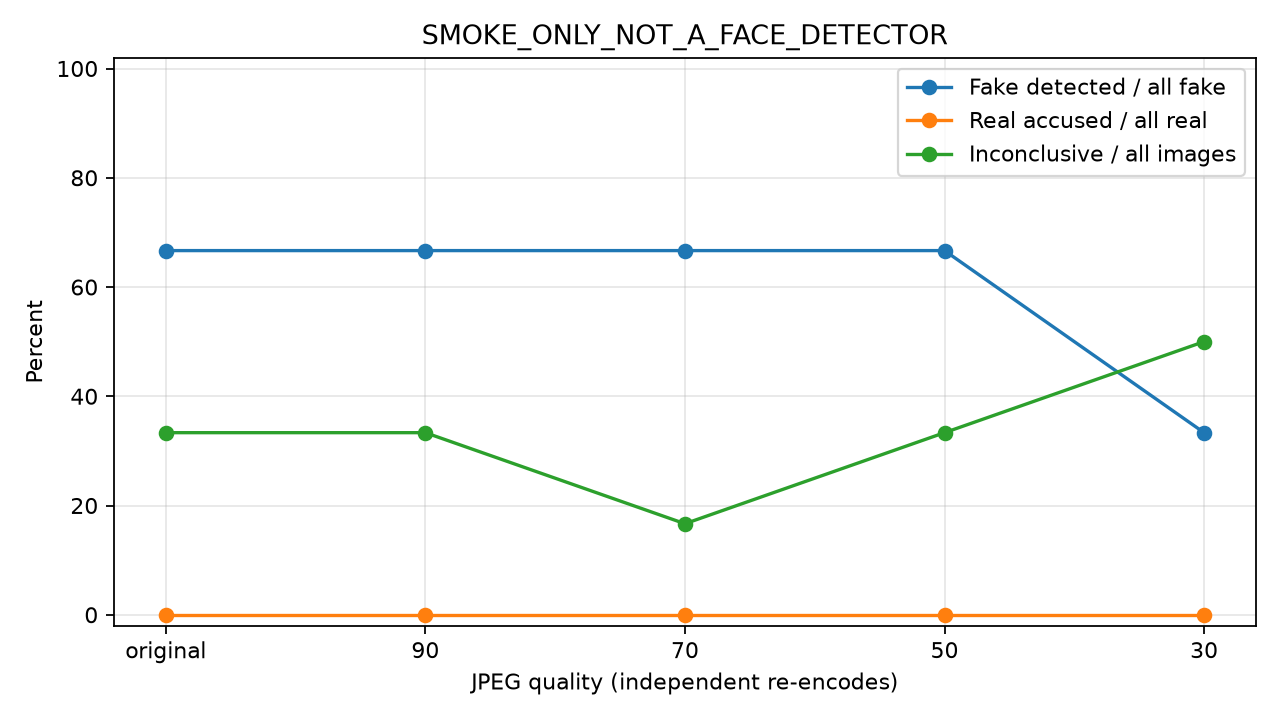

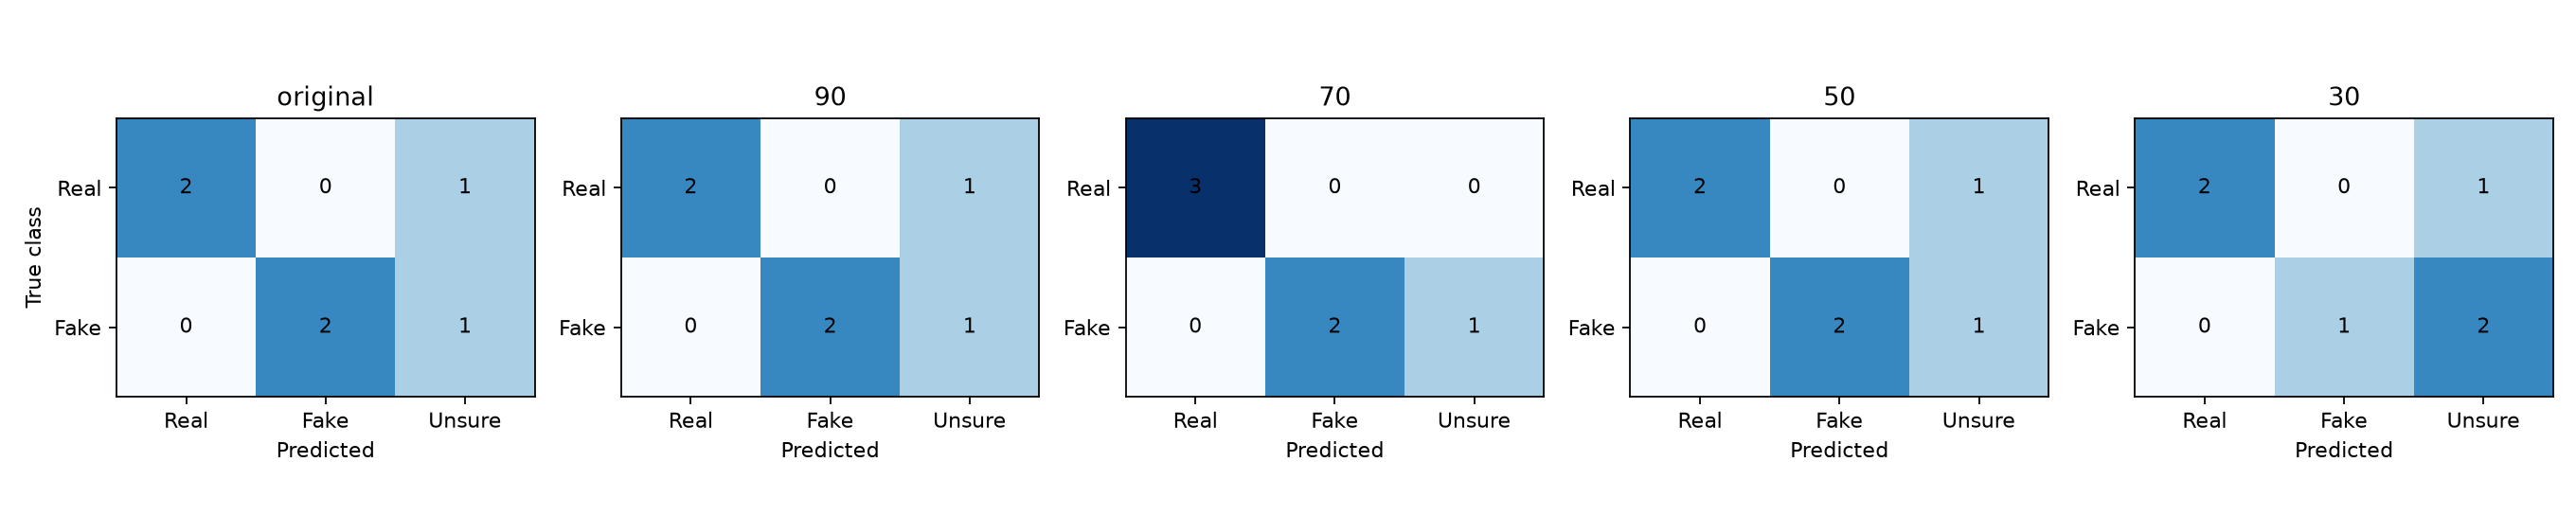

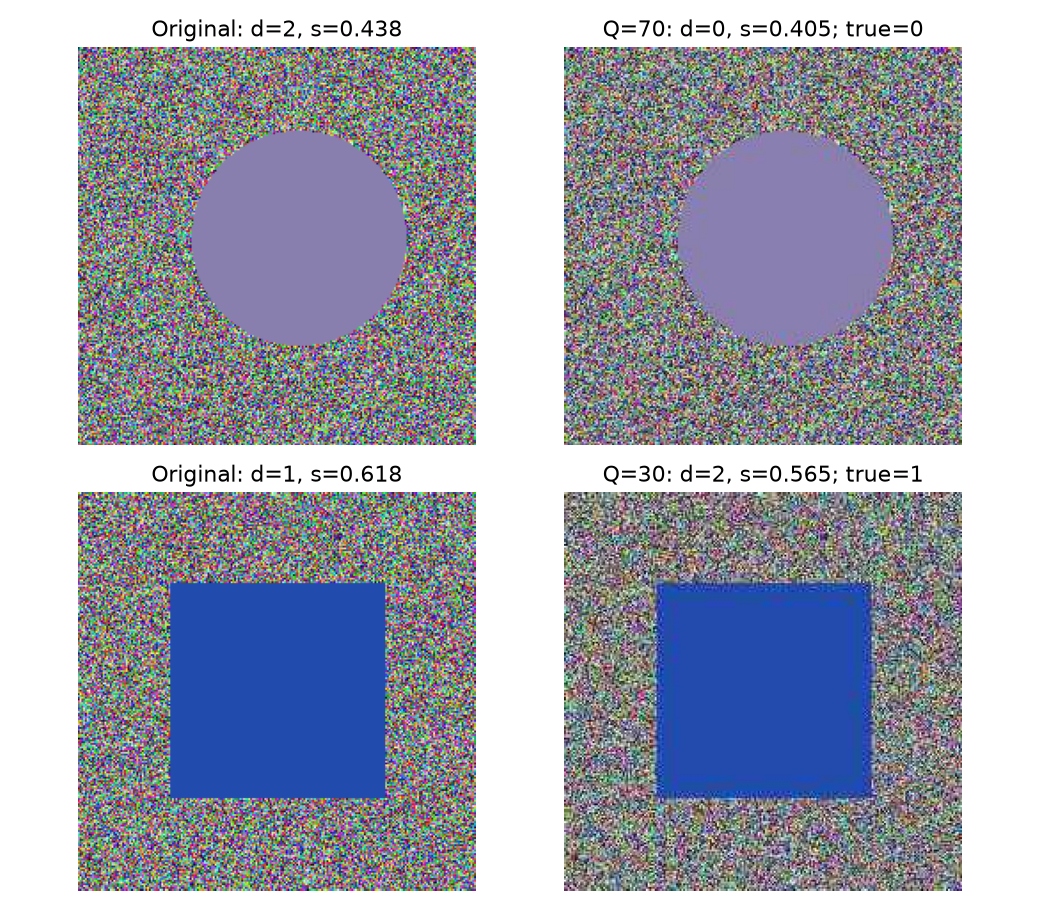

# تقرير تجربة JPEG — SMOKE_ONLY_NOT_A_FACE_DETECTOR

الدرجة ترجيح النموذج للفئة المولّدة، وليست إثباتًا للأصالة أو احتمالًا معايرًا.
خط الأساس original هو الأصل المفكوك بعد توحيد RGB والقص المركزي إلى 224×224، دون إعادة JPEG إضافية. كل جودة أُنشئت مستقلة منه، وليست سلسلة ضغط. قد يكون الأصل نفسه JPEG سابقًا.

نسبة اكتشاف المولّد = المولّد المحكوم عليه fake ÷ جميع المولّدات؛ الاتهام الخاطئ = الحقيقي المحكوم عليه fake ÷ جميع الصور الحقيقية. غير الحاسم يُعدّ ضمن المقام ولا يُحتسب اكتشافًا صحيحًا. الدقة الانتقائية مقامها الحالات المحسومة فقط؛ AUC تستخدم جميع الدرجات.

**هذه بيانات هندسية اصطناعية لاختبار البرمجيات فقط. لا تمثل صور أشخاص أو قدرة كشف التوليد. لا تُقدّم أرقامها كنتيجة علمية للمشروع.**

- الجودة original: اكتشف 2/3 مولّدة (66.7%)؛ اتّهم خطأً 0/3 فوتوغرافية (0.0%)؛ غير حاسم 2/6 (33.3%).
- الجودة 90: اكتشف 2/3 مولّدة (66.7%)؛ اتّهم خطأً 0/3 فوتوغرافية (0.0%)؛ غير حاسم 2/6 (33.3%).
- الجودة 70: اكتشف 2/3 مولّدة (66.7%)؛ اتّهم خطأً 0/3 فوتوغرافية (0.0%)؛ غير حاسم 1/6 (16.7%).
- الجودة 50: اكتشف 2/3 مولّدة (66.7%)؛ اتّهم خطأً 0/3 فوتوغرافية (0.0%)؛ غير حاسم 2/6 (33.3%).
- الجودة 30: اكتشف 1/3 مولّدة (33.3%)؛ اتّهم خطأً 0/3 فوتوغرافية (0.0%)؛ غير حاسم 3/6 (50.0%).

عند الجودة 30 تغيّر معدل اكتشاف المولّد بمقدار -33.3 نقطة مئوية، ومعدل الاتهام الخاطئ بمقدار +0.0 نقطة مقارنة بالأصل.
هذه مقارنة زوجية على الصور نفسها. لا يلزم أن يكون الأثر رتيبًا مع الجودة، ولا يجوز تعميمه على مولّدات أخرى أو صور الإنترنت. لا يمكن بهذه التجربة وحدها فصل بصمات المولّد عن بصمات مصدر البيانات.
العينة الصغيرة والتكرارات القريبة غير المكتشفة وغياب بيانات الهوية تحدّ الاستنتاج. يُفضّل تكرار التجربة على مصدر خارجي ومولّد غير مستخدم في التدريب.

In [8]:
from facejpeg.evaluate import evaluate
RESULTS = RUN / "evaluation"
table = evaluate(PREPARED, BEST, RESULTS, batch_size=BATCH_SIZE,
                 device="cpu" if QUICK else None)
display(table)
display(DisplayImage(filename=str(RESULTS / "jpeg_effect.png")))
display(DisplayImage(filename=str(RESULTS / "confusion_matrices.png")))
if (RESULTS / "changed_examples.png").exists():
    display(DisplayImage(filename=str(RESULTS / "changed_examples.png")))
else:
    print((RESULTS / "NO_CHANGED_EXAMPLES.txt").read_text())
display(Markdown((RESULTS / "REPORT_AR.md").read_text()))

## 9 — تجربة صورة ترفعها بنفسك
ارفع JPG/PNG يحتوي على وجه أمامي واحد واضح في المركز. يستخدم كاشف OpenCV بوابة بسيطة قد تُخطئ، ثم تُعرض النسختان والدرجتان. قد ترفض صورة بلا وجه أو بعدة وجوه برسالة عربية. الحكم ترجيح فقط. عند تشغيل fixture تُعرض رسالة أن النموذج اختبار برمجي غير صالح لاستنتاج أصالة الوجه.

In [ ]:
if IN_COLAB:
    from google.colab import files
    uploaded_image = files.upload()
    user_image = next(iter(uploaded_image))
else:
    user_image = input("مسار صورة JPG/PNG: ").strip()
try:
    comparison = predictor.compare(user_image, quality=70)
    display(comparison[0], comparison[1])
    display(Markdown(comparison[2] + "\n\n" + comparison[3] + "\n\n" + comparison[4]))
except ValueError as error:
    print(str(error))

## 10 — واجهة Gradio العربية
ارفع صورة واختر جودة الضغط لتظهر المقارنة جنبًا إلى جنب. في Colab يتطلب العرض عادة رابط Gradio مؤقتًا عامًا (`SHARE_GRADIO=True`)؛ شغّل هذه الخلية عندما تريد فتح الواجهة وأغلقها بعد التجربة. لا ترفع صورًا حساسة. محليًا: `python app.py --checkpoint runs/اسم_التجربة/best.pt` ولا حاجة إلى المشاركة العامة.

In [ ]:
from app import create_app
demo = create_app(BEST)
demo.launch(share=SHARE_GRADIO if IN_COLAB else False, debug=False)

## 11 — تنزيل نتائجك وشرحها
يحفظ ZIP التالي النموذج وlast.pt والتقسيم والصور المجهزة والتقارير حتى تستطيع الاستكمال؛ قد يكبر حجمه عند التدريب الكامل. احتفظ بمجلد Drive للتدريب الطويل. تقرير العرض: اشرح المصدر وحدوده، ومنع التسرب، واختيار الحدود، ثم قارن نسب Q30 بالأصل مع ذكر المقامات والحالات غير الحاسمة. راجع `docs/PRESENTATION_AR.md` لأفكار المناقشة. لا تسمِّ أرقام الاختبار البرمجي دقة مشروع كشف الوجوه.

In [ ]:
import shutil
result_zip = shutil.make_archive(str(PROJECT / (EXPERIMENT + "_results")), "zip", root_dir=RUN)
print(result_zip)
if IN_COLAB:
    from google.colab import files
    files.download(result_zip)